# HW3: Hyperparameter Tuning

This notebook trains a baseline classifier on the chest X-ray dataset to distinguish **NORMAL** from **PNEUMONIA** images.

It is organized as follows: import libraries → define training / validation / test functions → prepare data → build model → set hyperparameters and train → plot learning curves → evaluate on the test set.

Use this notebook as a starting point. You are free to modify any part of it (hyperparameters, model architecture, data augmentation, etc.) for your experiments, and summarize your findings in the analysis report.

# Import Library

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import random
import time
import torch
import torch.nn as nn
import torch.optim as optims

from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms.functional import InterpolationMode

This cell sets up the computing device and checks whether a GPU is available. Training on a GPU is much faster than on a CPU.

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
gpu_count = torch.cuda.device_count()

print("Using", gpu_count, "GPUs")
print("CUDA is available:", torch.cuda.is_available())

Using 1 GPUs
CUDA is available: True


This cell defines the three functions used throughout the homework:

- **`train_one_epoch`**: trains the model for one epoch on the training set (forward pass → loss → backpropagation → weight update) and returns the average loss and accuracy.
- **`val_one_epoch`**: evaluates the model on the validation set without updating weights, and saves the checkpoint with the best validation accuracy.
- **`evaluate`**: loads the saved best model and reports the final loss and accuracy on the test set.

In [13]:
# train loop
def train_one_epoch(model, device, criterion, optimizer, train_data_loader):
    epoch_loss = []
    epoch_acc = []
    start_time = time.time()

    model.train()

    for batch_idx, (images, labels) in enumerate (train_data_loader):
        images = images.to(device)
        labels = labels.to(device).float()
        optimizer.zero_grad()
        preds = model(images)
        loss = criterion(preds, labels.unsqueeze(1))

        # Calculating Loss
        epoch_loss.append(loss.item())

        # Calculating Metrics
        predicts = (preds > 0.5).float()
        predicts = predicts.view(-1)
        predicts = predicts.detach().cpu().numpy()
        labels = labels.detach().cpu().numpy()
        acc = accuracy_score(labels, predicts)

        epoch_acc.append(acc)

        # Backpropagation
        loss.backward()
        optimizer.step()

    # Overall Epoch Results
    end_time = time.time()
    total_time = end_time - start_time

    epoch_loss = np.mean(epoch_loss)
    epoch_acc = np.mean(epoch_acc) * 100

    return epoch_loss, epoch_acc, total_time

# validation loop
def val_one_epoch(model, device, criterion, val_data_loader, best_acc, save):
    epoch_loss = []
    epoch_acc = []
    start_time = time.time()

    model.eval()

    with torch.no_grad():
        for images, labels in val_data_loader:
            images = images.to(device)
            labels = labels.to(device).float()
            preds = model(images)

            # Calculating Loss
            loss = criterion(preds, labels.unsqueeze(1))
            epoch_loss.append(loss.item())

            # Calculating Metrics
            predicts = (preds > 0.5).float()
            predicts = predicts.view(-1)
            predicts = predicts.detach().cpu().numpy()
            labels = labels.detach().cpu().numpy()
            acc = accuracy_score(labels, predicts)
            epoch_acc.append(acc)

    # Overall Epoch Results
    end_time = time.time()
    total_time = end_time - start_time

    epoch_loss = np.mean(epoch_loss)
    epoch_acc = np.mean(epoch_acc) * 100

    # Saving best model
    if epoch_acc > best_acc:
        best_acc = epoch_acc
        torch.save(model.state_dict(), f"{save}.pth")

    return epoch_loss, epoch_acc, total_time, best_acc

# evaluate loop (test loop)
def evaluate(model, device, model_path, test_loader):
    try:
        model.load_state_dict(torch.load(model_path))
        print("Model weights loaded successfully.")
    except Exception as e:
        print("Warning: Failed to load model weights. Using randomly initialized weights instead.")
        print(e)

    model.to(device)
    model.eval()

    test_loss = []
    test_acc = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device).float()

            # Forward pass
            preds = model(images)

            # Calculating loss
            loss = criterion(preds, labels.unsqueeze(1))
            test_loss.append(loss.item())

            # Calculating accuracy
            predicts = (preds > 0.5).float()
            predicts = predicts.view(-1)
            predicts = predicts.detach().cpu().numpy()
            labels = labels.detach().cpu().numpy()
            acc = accuracy_score(labels, predicts)
            test_acc.append(acc)

    # Overall test results
    avg_test_loss = np.mean(test_loss)
    avg_test_acc = np.mean(test_acc) * 100

    print(f"Test Accuracy: {avg_test_acc:.2f}%")
    print(f"Test Loss: {avg_test_loss:.4f}")

    return avg_test_loss, avg_test_acc

# Data Preparation

Mount Google Drive so the notebook can read the dataset stored in your Drive.

In [4]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [5]:
!find /content/drive/MyDrive -type d -name HW3_data_set

/content/drive/MyDrive/HW3_data_set


In [6]:
!find /content/drive/MyDrive/HW3_data_set -maxdepth 2 -type d

/content/drive/MyDrive/HW3_data_set
/content/drive/MyDrive/HW3_data_set/test
/content/drive/MyDrive/HW3_data_set/test/NORMAL
/content/drive/MyDrive/HW3_data_set/test/PNEUMONIA
/content/drive/MyDrive/HW3_data_set/train
/content/drive/MyDrive/HW3_data_set/train/NORMAL
/content/drive/MyDrive/HW3_data_set/train/PNEUMONIA
/content/drive/MyDrive/HW3_data_set/val
/content/drive/MyDrive/HW3_data_set/val/NORMAL
/content/drive/MyDrive/HW3_data_set/val/PNEUMONIA


In [2]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
root = Path('/content/drive/MyDrive/HW3_data_set')
print('最終模型檔存在：', (root / 'model_wd0_seed42.pth').is_file())

Mounted at /content/drive
最終模型檔存在： True


In [3]:
import json
import shutil
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms.functional import InterpolationMode
from sklearn.metrics import confusion_matrix

root = Path('/content/drive/MyDrive/HW3_data_set')
local_test = Path('/content/hw3_test')

print('正在複製測試影像...', flush=True)
shutil.copytree(root / 'test', local_test, dirs_exist_ok=True)

test_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])
test_dataset = datasets.ImageFolder(local_test, transform=test_transform)
assert len(test_dataset) == 624
assert test_dataset.class_to_idx == {'NORMAL': 0, 'PNEUMONIA': 1}
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
print('測試影像：', len(test_dataset), flush=True)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(256 * 256, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 1),
    nn.Sigmoid()
)

checkpoint = root / 'model_wd0_seed42.pth'
model.load_state_dict(
    torch.load(checkpoint, map_location='cpu', weights_only=True)
)
model.eval()

y_true, y_pred = [], []
total_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        probabilities = model(images)
        targets = labels.float().unsqueeze(1)
        total_loss += nn.functional.binary_cross_entropy(
            probabilities, targets, reduction='sum'
        ).item()
        y_true.extend(labels.tolist())
        y_pred.extend(
            (probabilities > 0.5).int().view(-1).tolist()
        )

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
result = {
    'accuracy_pct': 100 * (cm[0, 0] + cm[1, 1]) / len(y_true),
    'loss': total_loss / len(y_true),
    'normal_recall_pct': 100 * cm[0, 0] / cm[0].sum(),
    'pneumonia_recall_pct': 100 * cm[1, 1] / cm[1].sum(),
    'confusion_matrix': cm.tolist(),
}

print(f"最終測試準確率：{result['accuracy_pct']:.2f}%")
print(f"測試 loss：{result['loss']:.4f}")
print(f"NORMAL 辨識率：{result['normal_recall_pct']:.2f}%")
print(f"PNEUMONIA 辨識率：{result['pneumonia_recall_pct']:.2f}%")
print('混淆矩陣：', result['confusion_matrix'])

with open(root / 'final_wd0_test_metrics.json', 'w') as f:
    json.dump(result, f, indent=2)

正在複製測試影像...
測試影像： 624
最終測試準確率：78.37%
測試 loss：0.5813
NORMAL 辨識率：49.15%
PNEUMONIA 辨識率：95.90%
混淆矩陣： [[115, 119], [16, 374]]


This cell prepares the data:

1. **Paths**: set the folders for the train / validation / test sets (change them to where you stored the dataset).
2. **Transforms**: resize every image to 256×256, convert it to a single grayscale channel, and turn it into a tensor. `train_transform` is applied only to the training set, so this is where data augmentation can be added.
3. **Datasets & DataLoaders**: `ImageFolder` labels each image by its folder name (NORMAL / PNEUMONIA), and `DataLoader` splits the data into batches.

In [90]:
# define folder path for each set
train_path = '/content/hw3_data/train'
test_path = '/content/hw3_data/test'
val_path = '/content/hw3_data/val'

# define transformation
train_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
])

common_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

# create datasets
train_dataset = datasets.ImageFolder(train_path, transform=train_transform)
test_dataset = datasets.ImageFolder(test_path, transform=common_transform)
val_dataset = datasets.ImageFolder(val_path, transform=common_transform)

# create dataloaders
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [91]:
print(train_dataset.transform)
print(val_dataset.transform)

Compose(
    Resize(size=(256, 256), interpolation=bicubic, max_size=None, antialias=True)
    Grayscale(num_output_channels=1)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    ToTensor()
)
Compose(
    Resize(size=(256, 256), interpolation=bicubic, max_size=None, antialias=True)
    Grayscale(num_output_channels=1)
    ToTensor()
)


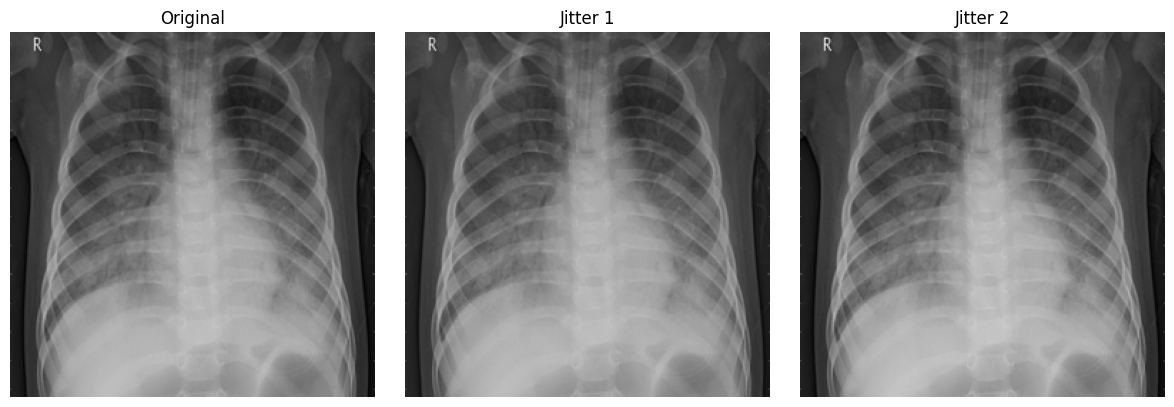

In [92]:
from PIL import Image
import matplotlib.pyplot as plt

image_path, _ = next(
    (path, label) for path, label in train_dataset.samples
    if label == 1
)

with Image.open(image_path) as image:
    pictures = [
        common_transform(image),
        train_transform(image),
        train_transform(image),
    ]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, picture, title in zip(
    axes, pictures, ['Original', 'Jitter 1', 'Jitter 2']
):
    ax.imshow(picture.squeeze(), cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [53]:
print(train_loader.batch_size, val_loader.batch_size, test_loader.batch_size)

64 64 64


In [17]:
print(len(train_dataset), len(val_dataset), len(test_dataset))
print(train_dataset.class_to_idx)

2001 16 624
{'NORMAL': 0, 'PNEUMONIA': 1}


# Model

This cell builds the baseline model: a fully connected network (MLP) that flattens each image into a vector and passes it through three hidden layers (Linear → BatchNorm → ReLU → Dropout). The final Sigmoid outputs the probability of pneumonia for binary classification.

In [93]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(256 * 256, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 1),
    nn.Sigmoid()
).to(device)

print('第一層：', type(model[0]).__name__)
print('參數量：', sum(p.numel() for p in model.parameters()))

第一層： Flatten
參數量： 4203137


In [60]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(256 * 256 * 1, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 1),
    nn.Sigmoid()
)

model.to(device)
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=65536, out_features=64, bias=True)
  (2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (3): ReLU()
  (4): Dropout(p=0.5, inplace=False)
  (5): Linear(in_features=64, out_features=64, bias=True)
  (6): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (7): ReLU()
  (8): Dropout(p=0.5, inplace=False)
  (9): Linear(in_features=64, out_features=64, bias=True)
  (10): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (11): ReLU()
  (12): Dropout(p=0.5, inplace=False)
  (13): Linear(in_features=64, out_features=1, bias=True)
  (14): Sigmoid()
)


In [67]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [77]:
model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d(1),

    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(64, 1),
    nn.Sigmoid()
).to(device)

print(model)
print('參數量：', sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU()
  (11): AdaptiveAvgPool2d(output_size=1)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Dropout(p=0.5, inplace=False)
  (14): Linear(in_features=64, out_features=1, bias=True)
  (15): Sigmoid()
)
參數量： 23585


In [79]:
mlp_model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(256 * 256, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 1),
    nn.Sigmoid()
).to(device)

mlp_test = evaluate_checkpoint(
    mlp_model, root / 'model_baseline_seed42.pth'
)

print(f"MLP 測試準確率：{mlp_test['accuracy_pct']:.2f}%")
print(f"NORMAL 辨識率：{mlp_test['normal_recall_pct']:.2f}%")
print(f"PNEUMONIA 辨識率：{mlp_test['pneumonia_recall_pct']:.2f}%")
print('混淆矩陣：', mlp_test['confusion_matrix'])

with open(root / 'mlp_seed42_test_metrics.json', 'w') as f:
    json.dump(mlp_test, f, indent=2)

MLP 測試準確率：83.49%
NORMAL 辨識率：64.53%
PNEUMONIA 辨識率：94.87%
混淆矩陣： [[151, 83], [20, 370]]


In [80]:
print(type(model[0]).__name__)

Conv2d


# Loop

This cell sets the training hyperparameters: learning rate, weight decay, learning rate scheduler, number of epochs, optimizer, and loss function (binary cross-entropy). `save` is the file name for the best model checkpoint.

In [94]:
# hyperparameter
lr = 0.001
weight_decay = 0.001
optimizer = optims.Adam(model.parameters(), lr=lr, weight_decay = weight_decay)
lr_scheduler = optims.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.1, patience=5, mode='max')
epochs = 10
criterion = nn.BCELoss()

# save checkpoint
save = '/content/drive/MyDrive/HW3_data_set/model_aug_jitter_seed42'

This cell runs the training loop. Each epoch trains on the training set, evaluates on the validation set, records the loss and accuracy, prints the results, and lets the learning rate scheduler adjust the learning rate based on the validation accuracy.

In [95]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_acc = 0.0
output_list = []

for epoch in range(epochs):
    train_loss, train_acc, train_time = train_one_epoch(model, device, criterion, optimizer, train_loader)
    val_loss, val_acc, val_time, best_acc = val_one_epoch(model, device, criterion, val_loader, best_acc, save)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    total_time = train_time + val_time
    output_str = f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - train_acc: {train_acc:.2f}% - val_loss: {val_loss:.4f} - val_acc: {val_acc:.2f}% - time: {total_time:.2f}s"
    output_list.append(output_str)
    print(output_str)
    lr_scheduler.step(val_acc)

Epoch 1/10 - loss: 0.5913 - train_acc: 68.95% - val_loss: 0.5516 - val_acc: 81.25% - time: 62.65s
Epoch 2/10 - loss: 0.4108 - train_acc: 86.01% - val_loss: 0.4895 - val_acc: 75.00% - time: 61.61s
Epoch 3/10 - loss: 0.2863 - train_acc: 91.47% - val_loss: 0.4550 - val_acc: 81.25% - time: 62.99s
Epoch 4/10 - loss: 0.2125 - train_acc: 93.48% - val_loss: 0.4261 - val_acc: 75.00% - time: 64.14s
Epoch 5/10 - loss: 0.1857 - train_acc: 94.09% - val_loss: 0.3122 - val_acc: 87.50% - time: 61.42s
Epoch 6/10 - loss: 0.1680 - train_acc: 94.88% - val_loss: 0.3613 - val_acc: 81.25% - time: 64.47s
Epoch 7/10 - loss: 0.1453 - train_acc: 95.09% - val_loss: 0.3270 - val_acc: 87.50% - time: 62.28s
Epoch 8/10 - loss: 0.1523 - train_acc: 94.69% - val_loss: 1.5488 - val_acc: 50.00% - time: 63.33s
Epoch 9/10 - loss: 0.1262 - train_acc: 95.38% - val_loss: 0.2720 - val_acc: 87.50% - time: 64.31s
Epoch 10/10 - loss: 0.1263 - train_acc: 95.71% - val_loss: 0.4720 - val_acc: 75.00% - time: 62.44s


In [96]:
import json
from pathlib import Path

root = Path('/content/drive/MyDrive/HW3_data_set')
jitter_history = {
    'train_loss': [float(x) for x in train_losses],
    'val_loss': [float(x) for x in val_losses],
    'train_accuracy_pct': [float(x) for x in train_accuracies],
    'val_accuracy_pct': [float(x) for x in val_accuracies],
}

path = root / 'jitter_seed42_history.json'
with open(path, 'w') as f:
    json.dump(jitter_history, f, indent=2)

print('已保存：', path, '輪數：', len(jitter_history['train_loss']))

已保存： /content/drive/MyDrive/HW3_data_set/jitter_seed42_history.json 輪數： 10


In [71]:
import json
from pathlib import Path

root = Path('/content/drive/MyDrive/HW3_data_set')
cnn_history = {
    'train_loss': [float(x) for x in train_losses],
    'val_loss': [float(x) for x in val_losses],
    'train_accuracy_pct': [float(x) for x in train_accuracies],
    'val_accuracy_pct': [float(x) for x in val_accuracies],
}

with open(root / 'cnn_seed42_history.json', 'w') as f:
    json.dump(cnn_history, f, indent=2)

best = cnn_history['val_accuracy_pct'].index(
    max(cnn_history['val_accuracy_pct'])
)
print('輪數：', len(cnn_history['train_loss']))
print(f"第10輪：訓練 {cnn_history['train_accuracy_pct'][-1]:.2f}%，"
      f"驗證 {cnn_history['val_accuracy_pct'][-1]:.2f}%")
print(f"最高驗證：{cnn_history['val_accuracy_pct'][best]:.2f}%，第 {best+1} 輪")
print('模型檔存在：', (root / 'model_cnn_seed42.pth').is_file())

輪數： 10
第10輪：訓練 90.13%，驗證 50.00%
最高驗證：87.50%，第 9 輪
模型檔存在： True


In [63]:
import json
from pathlib import Path

root = Path('/content/drive/MyDrive/HW3_data_set')
history = {
    'train_loss': [float(x) for x in train_losses],
    'val_loss': [float(x) for x in val_losses],
    'train_accuracy_pct': [float(x) for x in train_accuracies],
    'val_accuracy_pct': [float(x) for x in val_accuracies],
}

path = root / 'epochs15_seed42_history.json'
with open(path, 'w') as f:
    json.dump(history, f, indent=2)

print('已保存：', path, '輪數：', len(history['train_loss']))

已保存： /content/drive/MyDrive/HW3_data_set/epochs15_seed42_history.json 輪數： 15


In [49]:
import json
from pathlib import Path

root = Path('/content/drive/MyDrive/HW3_data_set')
batch32_history = {
    'train_loss': [float(x) for x in train_losses],
    'val_loss': [float(x) for x in val_losses],
    'train_accuracy_pct': [float(x) for x in train_accuracies],
    'val_accuracy_pct': [float(x) for x in val_accuracies],
}

with open(root / 'batch32_seed42_history.json', 'w') as f:
    json.dump(batch32_history, f, indent=2)

for name in (
    'model_baseline_seed42.pth',
    'baseline_seed42_history.json',
    'model_lr_0p0001_seed42.pth',
    'lr_0p0001_seed42_history.json',
    'model_batch32_seed42.pth',
    'batch32_seed42_history.json',
):
    print(name, '存在' if (root / name).is_file() else '找不到')

model_baseline_seed42.pth 存在
baseline_seed42_history.json 存在
model_lr_0p0001_seed42.pth 存在
lr_0p0001_seed42_history.json 存在
model_batch32_seed42.pth 存在
batch32_seed42_history.json 存在


In [42]:
import json

lr_history = {
    'train_loss': [float(x) for x in train_losses],
    'val_loss': [float(x) for x in val_losses],
    'train_accuracy_pct': [float(x) for x in train_accuracies],
    'val_accuracy_pct': [float(x) for x in val_accuracies],
}

history_path = '/content/drive/MyDrive/HW3_data_set/lr_0p0001_seed42_history.json'
with open(history_path, 'w') as f:
    json.dump(lr_history, f, indent=2)

print('已保存：', history_path)

已保存： /content/drive/MyDrive/HW3_data_set/lr_0p0001_seed42_history.json


In [32]:
import json

baseline_history = {
    'train_loss': [float(x) for x in train_losses],
    'val_loss': [float(x) for x in val_losses],
    'train_accuracy_pct': [float(x) for x in train_accuracies],
    'val_accuracy_pct': [float(x) for x in val_accuracies],
}

history_path = '/content/drive/MyDrive/HW3_data_set/baseline_seed42_history.json'
with open(history_path, 'w') as f:
    json.dump(baseline_history, f, indent=2)

print('已保存：', history_path)

已保存： /content/drive/MyDrive/HW3_data_set/baseline_seed42_history.json


In [15]:
from pathlib import Path
import shutil

src = Path('/content/drive/MyDrive/HW3_data_set')
dst = Path('/content/hw3_data')

for split in ('train', 'val', 'test'):
    shutil.copytree(src / split, dst / split, dirs_exist_ok=True)
    print(split, len(list((dst / split).rglob('*.jpeg'))))

train 2001
val 16
test 624


# Graph

This cell plots the training and validation loss and accuracy curves over epochs. Use them to check whether the model converges and whether it is overfitting or underfitting.

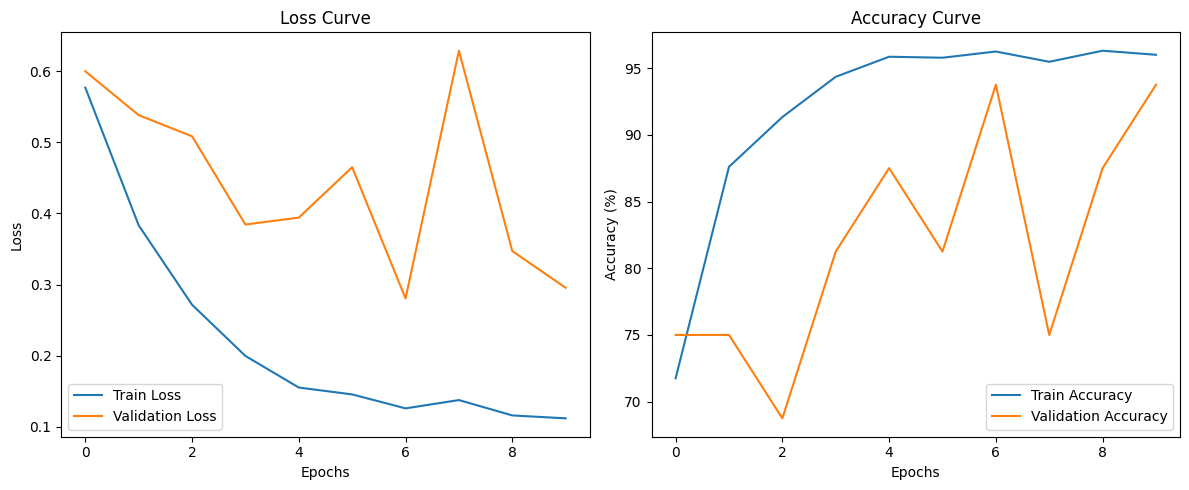

In [21]:
plt.figure(figsize=(12, 5))

# loss graph
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# accuracy graph
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()

# show
plt.tight_layout()
plt.show()

import json
from pathlib import Path
import matplotlib.pyplot as plt

root = Path('/content/drive/MyDrive/HW3_data_set')
files = {
    'Baseline (wd=0.001, 10 epochs)': 'baseline_seed42_history.json',
    'No weight decay (wd=0, 10 epochs)': 'wd0_seed42_history.json',
    'Longer training (wd=0.001, 15 epochs)': 'epochs15_seed42_history.json',
}
histories_step3 = {
    label: json.loads((root / filename).read_text())
    for label, filename in files.items()
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plots = [
    ('train_loss', 'Training loss'),
    ('val_loss', 'Validation loss'),
    ('train_accuracy_pct', 'Training accuracy (%)'),
    ('val_accuracy_pct', 'Validation accuracy (%)'),
]

for ax, (key, title) in zip(axes.flat, plots):
    for label, h in histories_step3.items():
        ax.plot(range(1, len(h[key]) + 1), h[key], marker='o', label=label)
    ax.set(title=title, xlabel='Epoch')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
fig.savefig(root / 'step3_learning_curves.png', dpi=200, bbox_inches='tight')
plt.show()

In [58]:
import json
from pathlib import Path

root = Path('/content/drive/MyDrive/HW3_data_set')
wd0_history = {
    'train_loss': [float(x) for x in train_losses],
    'val_loss': [float(x) for x in val_losses],
    'train_accuracy_pct': [float(x) for x in train_accuracies],
    'val_accuracy_pct': [float(x) for x in val_accuracies],
}

path = root / 'wd0_seed42_history.json'
with open(path, 'w') as f:
    json.dump(wd0_history, f, indent=2)

print('已保存：', path)

已保存： /content/drive/MyDrive/HW3_data_set/wd0_seed42_history.json


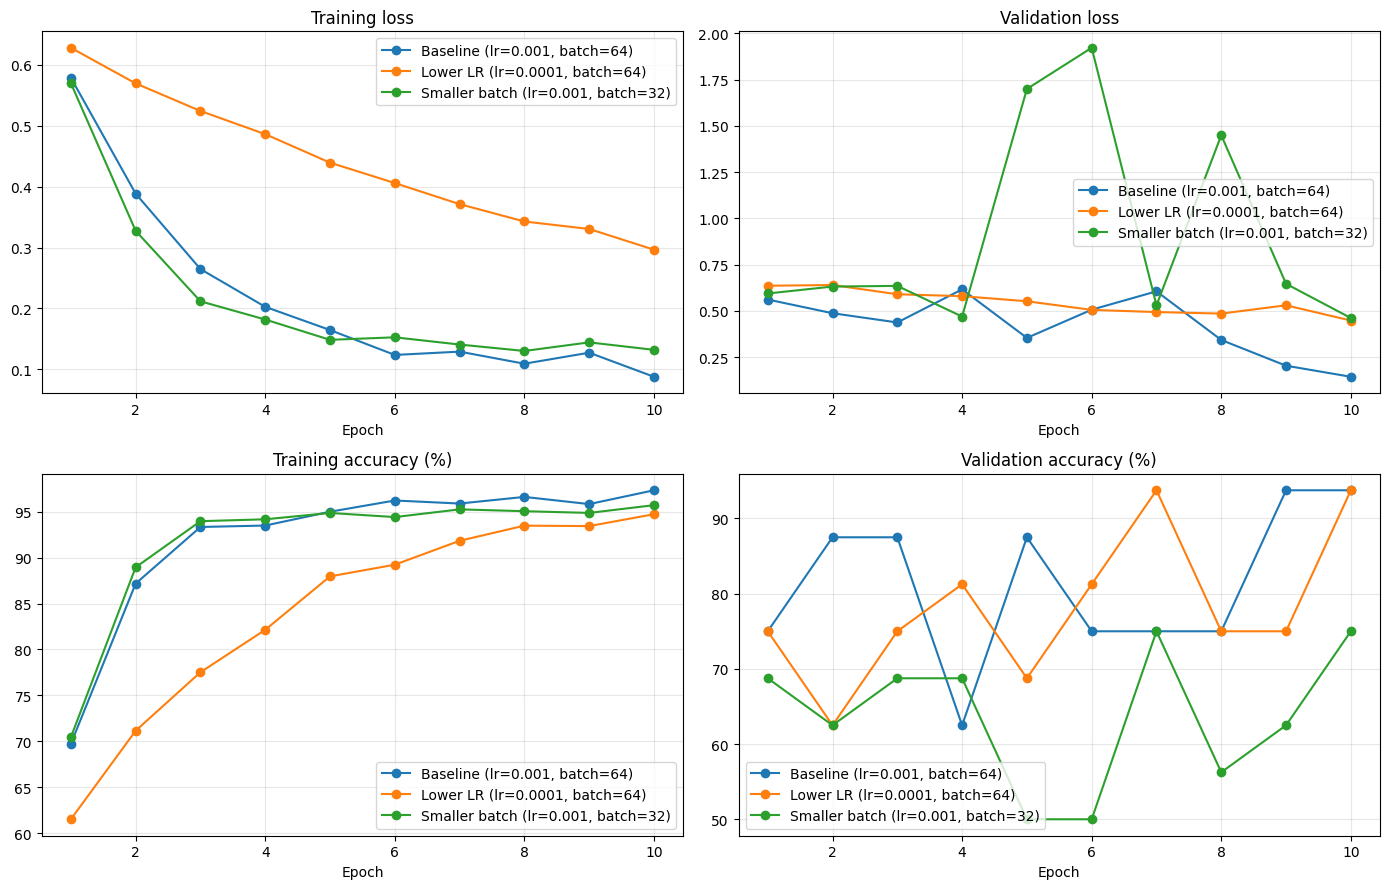

In [50]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

root = Path('/content/drive/MyDrive/HW3_data_set')
files = {
    'Baseline (lr=0.001, batch=64)': 'baseline_seed42_history.json',
    'Lower LR (lr=0.0001, batch=64)': 'lr_0p0001_seed42_history.json',
    'Smaller batch (lr=0.001, batch=32)': 'batch32_seed42_history.json',
}
histories = {
    label: json.loads((root / filename).read_text())
    for label, filename in files.items()
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plots = [
    ('train_loss', 'Training loss'),
    ('val_loss', 'Validation loss'),
    ('train_accuracy_pct', 'Training accuracy (%)'),
    ('val_accuracy_pct', 'Validation accuracy (%)'),
]

for ax, (key, title) in zip(axes.flat, plots):
    for label, history in histories.items():
        values = history[key]
        ax.plot(range(1, len(values) + 1), values, marker='o', label=label)
    ax.set(title=title, xlabel='Epoch')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
fig.savefig(root / 'step2_learning_curves.png', dpi=200, bbox_inches='tight')
plt.show()

In [51]:
import pandas as pd

rows = []
for label, h in histories.items():
    best_epoch = h['val_accuracy_pct'].index(max(h['val_accuracy_pct']))
    rows.append({
        'Setting': label,
        'Epoch 10 train loss': h['train_loss'][-1],
        'Epoch 10 train accuracy (%)': h['train_accuracy_pct'][-1],
        'Best validation accuracy (%)': h['val_accuracy_pct'][best_epoch],
        'Best epoch': best_epoch + 1,
        'Validation loss at best epoch': h['val_loss'][best_epoch],
    })

summary = pd.DataFrame(rows)
display(summary.round(3))
summary.to_csv(root / 'step2_summary.csv', index=False)

,Setting,Epoch 10 train loss,Epoch 10 train accuracy (%),Best validation accuracy (%),Best epoch,Validation loss at best epoch
0,"Baseline (lr=0.001, batch=64)",0.088,97.314,93.75,9,0.203
1,"Lower LR (lr=0.0001, batch=64)",0.296,94.712,93.75,7,0.493
2,"Smaller batch (lr=0.001, batch=32)",0.132,95.696,75.00,7,0.529


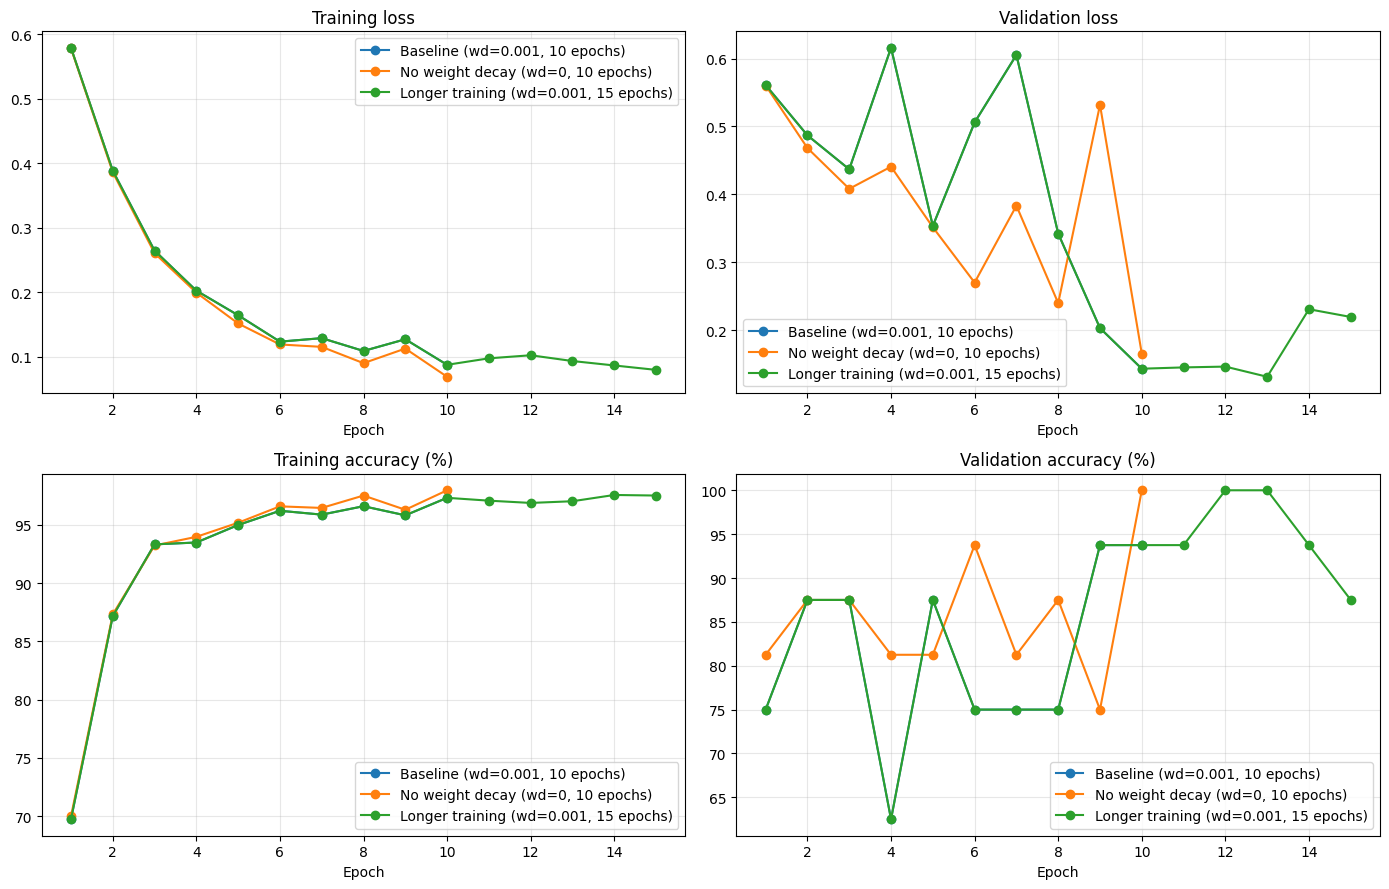

In [65]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

root = Path('/content/drive/MyDrive/HW3_data_set')
files = {
    'Baseline (wd=0.001, 10 epochs)': 'baseline_seed42_history.json',
    'No weight decay (wd=0, 10 epochs)': 'wd0_seed42_history.json',
    'Longer training (wd=0.001, 15 epochs)': 'epochs15_seed42_history.json',
}
histories_step3 = {
    label: json.loads((root / filename).read_text())
    for label, filename in files.items()
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plots = [
    ('train_loss', 'Training loss'),
    ('val_loss', 'Validation loss'),
    ('train_accuracy_pct', 'Training accuracy (%)'),
    ('val_accuracy_pct', 'Validation accuracy (%)'),
]

for ax, (key, title) in zip(axes.flat, plots):
    for label, h in histories_step3.items():
        ax.plot(range(1, len(h[key]) + 1), h[key], marker='o', label=label)
    ax.set(title=title, xlabel='Epoch')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
fig.savefig(root / 'step3_learning_curves.png', dpi=200, bbox_inches='tight')
plt.show()

In [66]:
import pandas as pd

rows = []
for label, h in histories_step3.items():
    best = h['val_accuracy_pct'].index(max(h['val_accuracy_pct']))
    rows.append({
        'Setting': label,
        'Epochs': len(h['train_loss']),
        'Train accuracy at epoch 10 (%)': h['train_accuracy_pct'][9],
        'Validation accuracy at epoch 10 (%)': h['val_accuracy_pct'][9],
        'Train-validation gap at epoch 10 (pp)':
            h['train_accuracy_pct'][9] - h['val_accuracy_pct'][9],
        'Best validation accuracy (%)': h['val_accuracy_pct'][best],
        'Best epoch': best + 1,
        'Final validation accuracy (%)': h['val_accuracy_pct'][-1],
    })

step3_summary = pd.DataFrame(rows)
display(step3_summary.round(2))
step3_summary.to_csv(root / 'step3_summary.csv', index=False)

,Setting,Epochs,Train accuracy at epoch 10 (%),Validation accuracy at epoch 10 (%),Train-validation gap at epoch 10 (pp),Best validation accuracy (%),Best epoch,Final validation accuracy (%)
0,"Baseline (wd=0.001, 10 epochs)",10,97.31,93.75,3.56,93.75,9,93.75
1,"No weight decay (wd=0, 10 epochs)",10,97.96,100.00,-2.04,100.00,10,100.00
2,"Longer training (wd=0.001, 15 epochs)",15,97.31,93.75,3.56,100.00,12,87.50


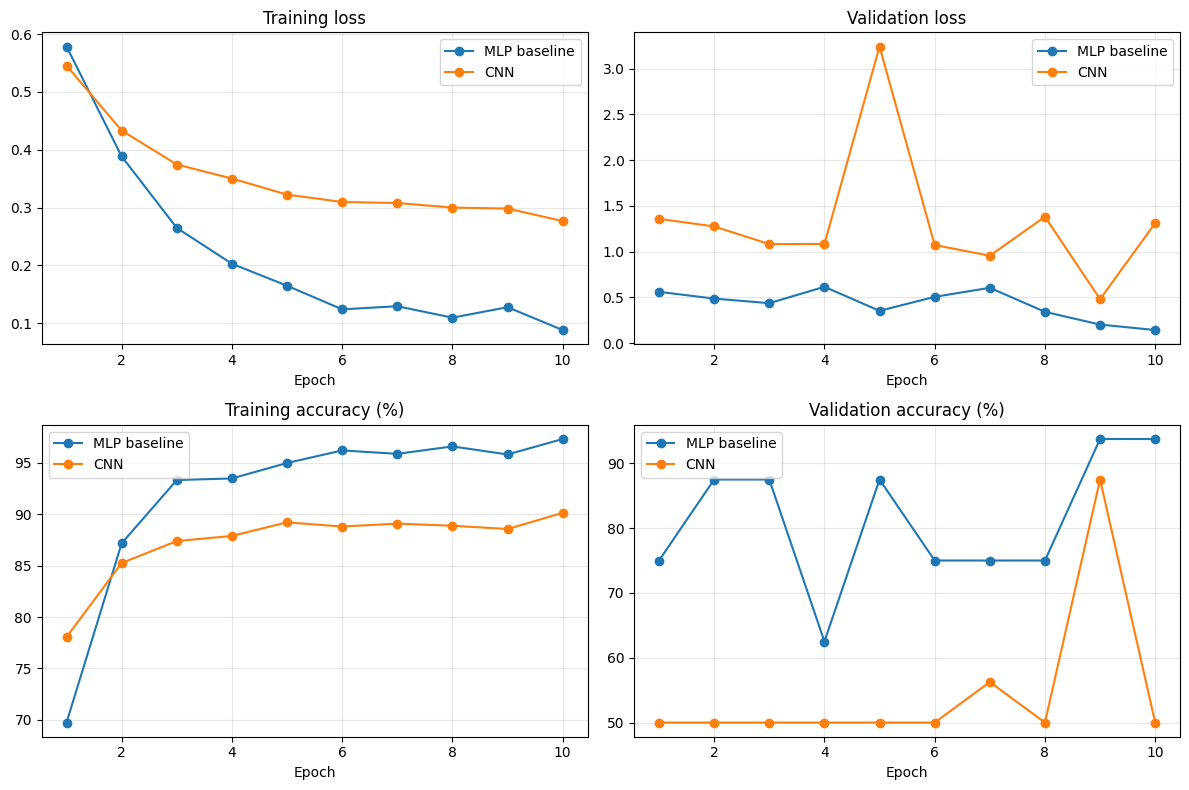

In [72]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

root = Path('/content/drive/MyDrive/HW3_data_set')
models = {
    'MLP baseline': json.loads(
        (root / 'baseline_seed42_history.json').read_text()
    ),
    'CNN': json.loads(
        (root / 'cnn_seed42_history.json').read_text()
    ),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plots = [
    ('train_loss', 'Training loss'),
    ('val_loss', 'Validation loss'),
    ('train_accuracy_pct', 'Training accuracy (%)'),
    ('val_accuracy_pct', 'Validation accuracy (%)'),
]

for ax, (key, title) in zip(axes.flat, plots):
    for name, h in models.items():
        ax.plot(range(1, len(h[key]) + 1), h[key], marker='o', label=name)
    ax.set(title=title, xlabel='Epoch')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
fig.savefig(root / 'step4_mlp_cnn_curves.png', dpi=200, bbox_inches='tight')
plt.show()

In [73]:
import pandas as pd

parameter_counts = {
    'MLP baseline': 4_203_137,
    'CNN': 23_585,
}

rows = []
for name, h in models.items():
    best = h['val_accuracy_pct'].index(max(h['val_accuracy_pct']))
    rows.append({
        'Model': name,
        'Parameters': parameter_counts[name],
        'Epoch 10 train accuracy (%)': h['train_accuracy_pct'][-1],
        'Epoch 10 validation accuracy (%)': h['val_accuracy_pct'][-1],
        'Epoch 10 train-validation gap (pp)':
            h['train_accuracy_pct'][-1] - h['val_accuracy_pct'][-1],
        'Best validation accuracy (%)': h['val_accuracy_pct'][best],
        'Best epoch': best + 1,
    })

step4_summary = pd.DataFrame(rows)
display(step4_summary.round(2))
step4_summary.to_csv(root / 'step4_summary.csv', index=False)

,Model,Parameters,Epoch 10 train accuracy (%),Epoch 10 validation accuracy (%),Epoch 10 train-validation gap (pp),Best validation accuracy (%),Best epoch
0,MLP baseline,4203137,97.31,93.75,3.56,93.75,9
1,CNN,23585,90.13,50.00,40.13,87.50,9


In [74]:
from sklearn.metrics import confusion_matrix

def evaluate_checkpoint(model, checkpoint):
    assert checkpoint.is_file(), f'找不到模型：{checkpoint}'
    model.load_state_dict(
        torch.load(checkpoint, map_location=device, weights_only=True)
    )
    model.to(device).eval()

    y_true, y_pred = [], []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in test_loader:
            probabilities = model(images.to(device))
            targets = labels.float().unsqueeze(1).to(device)
            total_loss += nn.functional.binary_cross_entropy(
                probabilities, targets, reduction='sum'
            ).item()
            y_true.extend(labels.tolist())
            y_pred.extend(
                (probabilities > 0.5).int().cpu().view(-1).tolist()
            )

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    return {
        'accuracy_pct': 100 * (cm[0, 0] + cm[1, 1]) / len(y_true),
        'loss': total_loss / len(y_true),
        'normal_recall_pct': 100 * cm[0, 0] / cm[0].sum(),
        'pneumonia_recall_pct': 100 * cm[1, 1] / cm[1].sum(),
        'confusion_matrix': cm.tolist(),
    }

assert isinstance(model[0], nn.Conv2d), '目前的 model 不是 CNN'
cnn_test = evaluate_checkpoint(model, root / 'model_cnn_seed42.pth')

print(f"CNN 測試準確率：{cnn_test['accuracy_pct']:.2f}%")
print(f"NORMAL 辨識率：{cnn_test['normal_recall_pct']:.2f}%")
print(f"PNEUMONIA 辨識率：{cnn_test['pneumonia_recall_pct']:.2f}%")
print('混淆矩陣：', cnn_test['confusion_matrix'])

with open(root / 'cnn_test_metrics.json', 'w') as f:
    json.dump(cnn_test, f, indent=2)

CNN 測試準確率：81.41%
NORMAL 辨識率：80.77%
PNEUMONIA 辨識率：81.79%
混淆矩陣： [[189, 45], [71, 319]]


In [82]:
test_metrics = {
    'MLP baseline': mlp_test,
    'CNN': cnn_test,
}

for column, key in (
    ('Test accuracy (%)', 'accuracy_pct'),
    ('NORMAL recall (%)', 'normal_recall_pct'),
    ('PNEUMONIA recall (%)', 'pneumonia_recall_pct'),
    ('Test loss', 'loss'),
):
    step4_summary[column] = step4_summary['Model'].map(
        lambda name: test_metrics[name][key]
    )

display(step4_summary.round(2))
step4_summary.to_csv(root / 'step4_summary.csv', index=False)

,Model,Parameters,Epoch 10 train accuracy (%),Epoch 10 validation accuracy (%),Epoch 10 train-validation gap (pp),Best validation accuracy (%),Best epoch,Test accuracy (%),NORMAL recall (%),PNEUMONIA recall (%),Test loss
0,MLP baseline,4203137,97.31,93.75,3.56,93.75,9,83.49,64.53,94.87,0.43
1,CNN,23585,90.13,50.00,40.13,87.50,9,81.41,80.77,81.79,0.43


In [89]:
import json
from pathlib import Path

root = Path('/content/drive/MyDrive/HW3_data_set')
rotation_history = {
    'train_loss': [float(x) for x in train_losses],
    'val_loss': [float(x) for x in val_losses],
    'train_accuracy_pct': [float(x) for x in train_accuracies],
    'val_accuracy_pct': [float(x) for x in val_accuracies],
}

with open(root / 'rotation5_seed42_history.json', 'w') as f:
    json.dump(rotation_history, f, indent=2)

best = rotation_history['val_accuracy_pct'].index(
    max(rotation_history['val_accuracy_pct'])
)
print('輪數：', len(rotation_history['train_loss']))
print(f"第10輪訓練準確率：{rotation_history['train_accuracy_pct'][-1]:.2f}%")
print(f"第10輪驗證準確率：{rotation_history['val_accuracy_pct'][-1]:.2f}%")
print(f"最高驗證準確率：{rotation_history['val_accuracy_pct'][best]:.2f}%，第 {best+1} 輪")

輪數： 10
第10輪訓練準確率：95.53%
第10輪驗證準確率：93.75%
最高驗證準確率：93.75%，第 2 輪


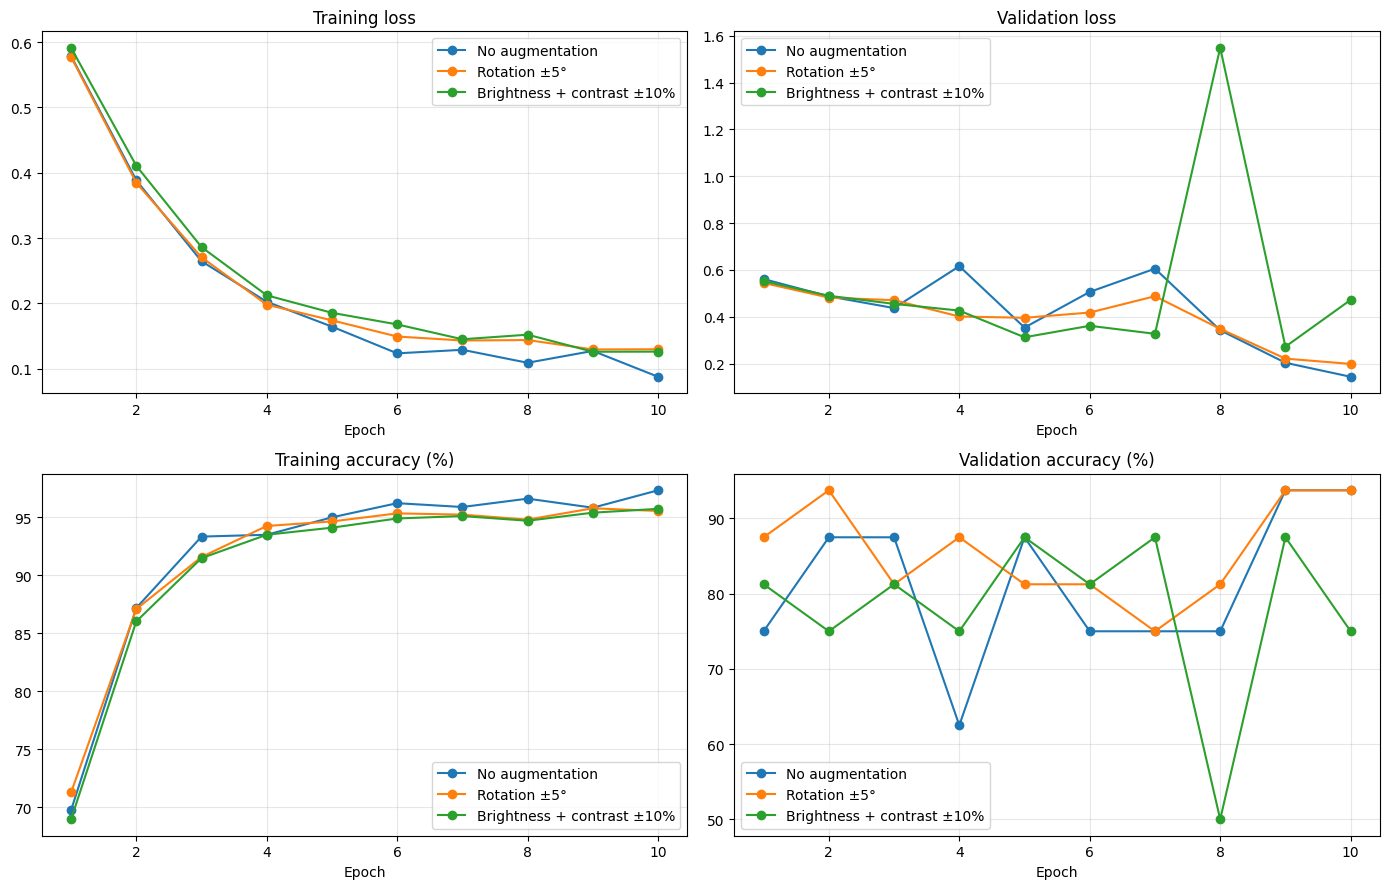

,Augmentation,Epoch 10 train accuracy (%),Epoch 10 validation accuracy (%),Best validation accuracy (%),Best epoch,Validation loss at best epoch
0,No augmentation,97.314,93.75,93.75,9,0.203
1,Rotation ±5°,95.531,93.75,93.75,2,0.482
2,Brightness + contrast ±10%,95.715,75.00,87.50,5,0.312


In [97]:
import json
import pandas as pd
import matplotlib.pyplot as plt

files = {
    'No augmentation': 'baseline_seed42_history.json',
    'Rotation ±5°': 'rotation5_seed42_history.json',
    'Brightness + contrast ±10%': 'jitter_seed42_history.json',
}
aug_histories = {
    name: json.loads((root / filename).read_text())
    for name, filename in files.items()
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plots = [
    ('train_loss', 'Training loss'),
    ('val_loss', 'Validation loss'),
    ('train_accuracy_pct', 'Training accuracy (%)'),
    ('val_accuracy_pct', 'Validation accuracy (%)'),
]

for ax, (key, title) in zip(axes.flat, plots):
    for name, h in aug_histories.items():
        ax.plot(range(1, 11), h[key], marker='o', label=name)
    ax.set(title=title, xlabel='Epoch')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
fig.savefig(root / 'step5_learning_curves.png', dpi=200, bbox_inches='tight')
plt.show()

rows = []
for name, h in aug_histories.items():
    best = h['val_accuracy_pct'].index(max(h['val_accuracy_pct']))
    rows.append({
        'Augmentation': name,
        'Epoch 10 train accuracy (%)': h['train_accuracy_pct'][-1],
        'Epoch 10 validation accuracy (%)': h['val_accuracy_pct'][-1],
        'Best validation accuracy (%)': h['val_accuracy_pct'][best],
        'Best epoch': best + 1,
        'Validation loss at best epoch': h['val_loss'][best],
    })

step5_summary = pd.DataFrame(rows)
display(step5_summary.round(3))
step5_summary.to_csv(root / 'step5_summary.csv', index=False)

In [1]:
assert isinstance(model[0], nn.Flatten), '目前的 model 不是 MLP'

final_test = evaluate_checkpoint(
    model, root / 'model_wd0_seed42.pth'
)

print(f"最終測試準確率：{final_test['accuracy_pct']:.2f}%")
print(f"測試 loss：{final_test['loss']:.4f}")
print(f"NORMAL 辨識率：{final_test['normal_recall_pct']:.2f}%")
print(f"PNEUMONIA 辨識率：{final_test['pneumonia_recall_pct']:.2f}%")
print('混淆矩陣：', final_test['confusion_matrix'])

with open(root / 'final_wd0_test_metrics.json', 'w') as f:
    json.dump(final_test, f, indent=2)

NameError: name 'model' is not defined

# Evaluate

This cell loads the best checkpoint saved during training and evaluates it on the test set, which the model has never seen, to report its final performance.

In [22]:
from pathlib import Path

model_path = '/content/drive/MyDrive/HW3_data_set/model_baseline.pth'
assert Path(model_path).is_file(), f'找不到模型：{model_path}'

avg_test_loss, avg_test_acc = evaluate(
    model, device, model_path, test_loader
)

Model weights loaded successfully.
Test Accuracy: 85.52%
Test Loss: 0.3335


In [24]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_true, y_pred = [], []
model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        probabilities = model(images.to(device)).squeeze(1)
        y_true.extend(labels.tolist())
        y_pred.extend((probabilities >= 0.5).int().cpu().tolist())

print(f"逐張計算的準確率：{accuracy_score(y_true, y_pred):.2%}")
print("混淆矩陣（列：真實 NORMAL、PNEUMONIA；欄：預測 NORMAL、PNEUMONIA）")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

逐張計算的準確率：85.26%
混淆矩陣（列：真實 NORMAL、PNEUMONIA；欄：預測 NORMAL、PNEUMONIA）
[[161  73]
 [ 19 371]]


In [4]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

root = Path('/content/drive/MyDrive/HW3_data_set')
zip_path = Path('/content/HW3_results.zip')

result_files = [
    p for p in root.iterdir()
    if p.is_file() and p.suffix.lower() in {'.json', '.csv', '.png'}
]

with ZipFile(zip_path, 'w', ZIP_DEFLATED) as z:
    for p in result_files:
        z.write(p, arcname=p.name)

print(f'已打包 {len(result_files)} 個檔案：{zip_path}')
files.download(str(zip_path))

已打包 19 個檔案：/content/HW3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>